# 02 – Dense SIFT

Dense SIFT uses a regular grid of locations instead of relying on the detector to choose keypoints. The descriptor itself is still SIFT.

# Project setup

This notebook uses the shared functions in `visual_search/`.

In [ ]:
from pathlib import Path
import sys

# Mount Google Drive when this notebook is running in Colab.
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

PROJECT_ROOT = Path("/content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3")
DATASET_SOURCE = Path("/content/drive/MyDrive/cvpr_coursework/MSRC_ObjCategImageDatabase_v2")

if not (PROJECT_ROOT / "cvpr").is_dir():
    raise FileNotFoundError("Set PROJECT_ROOT to the folder containing cvpr/ and visual_search/.")
if not (PROJECT_ROOT / "visual_search").is_dir():
    raise FileNotFoundError("The visual_search package is missing from PROJECT_ROOT.")

sys.path.insert(0, str(PROJECT_ROOT))
print("Project:", PROJECT_ROOT)

Mounted at /content/drive
Project: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from cvpr.dataset import load_split_records, read_rgb
from cvpr.baseline import global_rgb_histogram
from cvpr.retrieval import compute_descriptors
from cvpr.evaluation import evaluate_retrieval, per_category_summary
from cvpr.plotting import show_ranked_results

from visual_search.features import create_sift
from visual_search.cache import feature_cache_path, load_feature_cache

MANIFEST = PROJECT_ROOT / "split_manifest.csv"
gallery, dev, test = load_split_records(
    DATASET_SOURCE,
    manifest_path=MANIFEST,
    extract_dir=PROJECT_ROOT / "data",
)
assert (len(gallery), len(dev), len(test)) == (391, 100, 100)
print(f"Loaded {len(gallery)} gallery, {len(dev)} development and {len(test)} test images.")

Loaded 391 gallery, 100 development and 100 test images.


In [ ]:
import cv2
import csv
from visual_search.features import extract_dense_sift, create_sift
from visual_search.cache import cache_gallery_features, feature_cache_path, load_feature_cache

GRID_STEP = 12
KEYPOINT_SIZE = 16
KEYPOINT_ANGLE = 0
DENSE_CACHE = PROJECT_ROOT / "sift_cache" / "dense_sift_step12_size16"

sift = create_sift()
dense_counts = cache_gallery_features(
    gallery,
    DENSE_CACHE,
    extractor=lambda image: extract_dense_sift(
        image, sift=sift, step=GRID_STEP,
        keypoint_size=KEYPOINT_SIZE, angle=KEYPOINT_ANGLE,
    ),
    expected_dimension=128,
    rebuild=False,
)
print("Dense SIFT cache contains", len(dense_counts), "images.")

Processed 50/391 images
Processed 100/391 images
Processed 150/391 images
Processed 200/391 images
Processed 250/391 images
Processed 300/391 images
Processed 350/391 images
Processed 391/391 images
Dense SIFT cache contains 391 images.


In [ ]:
detected_cache = PROJECT_ROOT / "sift_cache" / "detected_sift"
detected_counts = []
for index, record in enumerate(gallery):
    detected_path = feature_cache_path(detected_cache, index, record)
    dense_path = feature_cache_path(DENSE_CACHE, index, record)
    detected = load_feature_cache(detected_path, record.filename, 128)
    dense = load_feature_cache(dense_path, record.filename, 128)
    detected_counts.append(detected.shape[0])
    assert dense.shape[0] == dense_counts[index]

print("Detected SIFT mean:", round(float(np.mean(detected_counts)), 2))
print("Dense SIFT mean:", round(float(np.mean(dense_counts)), 2))
print("Detected SIFT minimum:", int(np.min(detected_counts)))
print("Dense SIFT minimum:", int(np.min(dense_counts)))

Detected SIFT mean: 464.03
Dense SIFT mean: 450.91
Detected SIFT minimum: 3
Dense SIFT minimum: 442


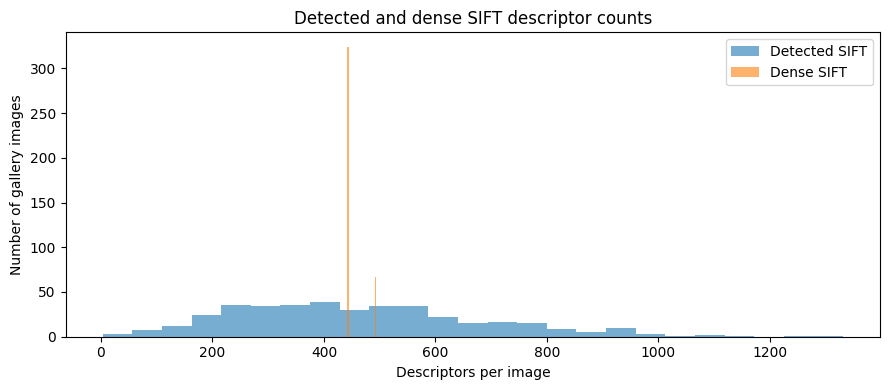

In [ ]:
plt.figure(figsize=(9, 4))
plt.hist(detected_counts, bins=25, alpha=0.6, label="Detected SIFT")
plt.hist(dense_counts, bins=25, alpha=0.6, label="Dense SIFT")
plt.xlabel("Descriptors per image")
plt.ylabel("Number of gallery images")
plt.title("Detected and dense SIFT descriptor counts")
plt.legend()
plt.tight_layout()
plt.show()

group_rows = []
for group in sorted({record.category for record in gallery}):
    indices = [i for i, record in enumerate(gallery) if record.category == group]
    detected_mean = float(np.mean([detected_counts[i] for i in indices]))
    dense_mean = float(np.mean([dense_counts[i] for i in indices]))
    group_rows.append({
        "group": group,
        "images": len(indices),
        "detected_mean": detected_mean,
        "dense_mean": dense_mean,
        "dense_to_detected_ratio": dense_mean / detected_mean,
    })

results_dir = PROJECT_ROOT / "results"
results_dir.mkdir(exist_ok=True)
with (results_dir / "detected_vs_dense_by_group.csv").open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=group_rows[0].keys())
    writer.writeheader()
    writer.writerows(group_rows)

## Compare the sampling patterns on one image

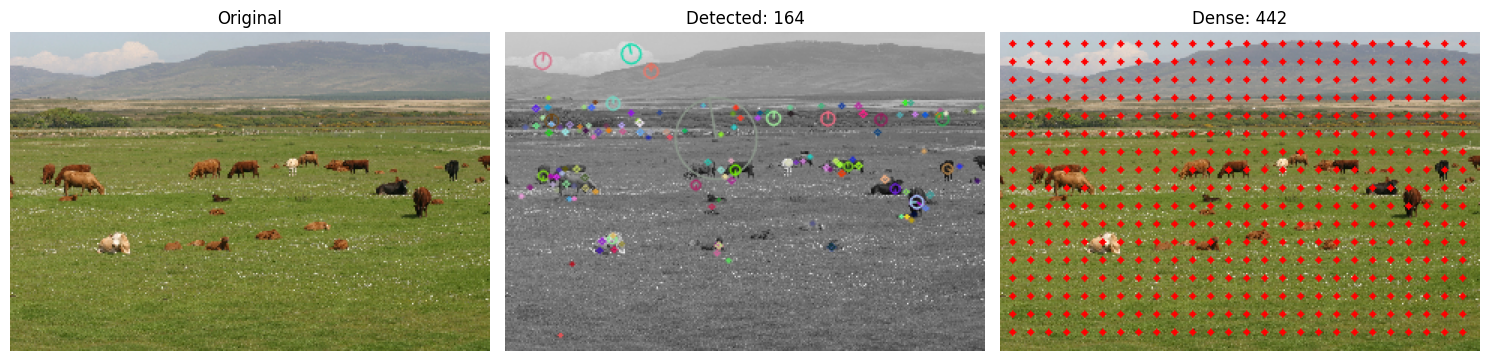

In [ ]:
query_index = 0
record = gallery[query_index]
image = read_rgb(record.path)
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
sift = create_sift()
detected_points, _ = sift.detectAndCompute(gray, None)
dense_descriptors, dense_info = load_feature_cache(
    feature_cache_path(DENSE_CACHE, query_index, record), record.filename,
    128, include_keypoints=True,
)
from visual_search.features import keypoints_from_array
dense_points = keypoints_from_array(dense_info)

detected_view = cv2.drawKeypoints(gray, detected_points, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
dense_view = image.copy()
for point in dense_points:
    x, y = point.pt
    cv2.circle(dense_view, (int(round(x)), int(round(y))), 2, (255, 0, 0), -1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(image); axes[0].set_title("Original")
axes[1].imshow(cv2.cvtColor(detected_view, cv2.COLOR_BGR2RGB)); axes[1].set_title(f"Detected: {len(detected_points)}")
axes[2].imshow(dense_view); axes[2].set_title(f"Dense: {len(dense_points)}")
for axis in axes: axis.axis("off")
plt.tight_layout(); plt.show()